# Módulo 14: Inocuidad

## 1. Objetivo

Estudiar las respuestas sobre inocuidad de las unidades agropecuarias (UA) vinculadas a los 22 grupos de cultivos seleccionados, en Lima, Ica, Arequipa, Junín y San Martín. El módulo 03 identifica los cultivos y los periodos de cosecha. El módulo 14 agrega las respuestas sobre información estatal, identificación de alimentos, manejo de residuos y conocimiento de límites de contaminantes.

## 2. Variables y datos

El módulo 14 recoge información declarada por las unidades agropecuarias (UA) sobre el manejo de residuos, la contaminación de alimentos y el conocimiento de requisitos sanitarios. Las principales variables utilizadas son:

- **`P204_NOM` y `P204_COD`:** nombre y código oficial del cultivo cosechado. `cultivo_grupo` corresponde a una agrupación creada para el análisis.
- **`P206_INI_MES`, `P206_INI_ANIO`, `P207_FIN_MES` y `P207_FIN_ANIO`:** mes y año de inicio y finalización real o prevista de la cosecha.
- **`P604`:** información recibida de una entidad del Estado sobre contaminación de alimentos. `1 = Sí`, `2 = No`.
- **`P607` y `P606_7`:** conocimiento del requisito de identificación de productos primarios para consumo humano. En `P607`, `1 = Sí` y `2 = No`. Se consideran las UA con `P606_7 = 0`; el valor `1` indica que no produce alimentos de consumo humano.
- **`P601_1` a `P601_6`:** manejo de residuos de cultivos: quema, alimento para animales, bota, abono (`P601_4`), deja en el campo y otro. `1 = Marcada`, `0 = Sin marcar`.
- **`P601_7`:** identifica a quienes no son productores agrícolas (`1`). Para analizar residuos se consideran las UA con valor `0`.
- **`P605A`:** conocimiento de los límites máximos permisibles de contaminantes en alimentos de consumo humano y/o animal. `1 = Sí`, `2 = No`. Se incluyen las respuestas válidas de todas las UA enlazadas, incluso si respondieron No en `P604`.

Los códigos y significados se recuperaron en las hojas `03_CAP200AB` y `14_CAP600`.

Para `P601`, se requieren valores `0` o `1` en las seis opciones y al menos una marcada. La elegibilidad de `P607` también se contrastó con los datos del Parquet. Estos criterios no cuentan con una verificación completa de los saltos del cuestionario de 2025.

## 3. Lectura de datos y diccionario

Se utilizan `03_CAP200AB.parquet`, `14_CAP600.parquet` y `DICC_ENA_2025.xlsx`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ruta_datos = "../data/raw/"
llave_ua = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "ID_PROD", "UA"]
departamentos = {15: "Lima", 11: "Ica", 4: "Arequipa", 12: "Junín", 22: "San Martín"}
fechas = ["P206_INI_MES", "P206_INI_ANIO", "P207_FIN_MES", "P207_FIN_ANIO"]
opciones_residuos = ["P601_1", "P601_2", "P601_3", "P601_4", "P601_5", "P601_6"]
preguntas_14 = ["P604", "P605A", "P607", "P606_7", "P601_7"] + opciones_residuos

In [3]:
cosechas = pd.read_parquet(ruta_datos + "03_CAP200AB.parquet",
    columns=llave_ua + ["NOMBREDD", "P204_NOM", "P204_COD"] + fechas)
inocuidad = pd.read_parquet(ruta_datos + "14_CAP600.parquet",
    columns=llave_ua + ["NOMBREDD"] + preguntas_14)
diccionario_14 = pd.read_excel(ruta_datos + "DICC_ENA_2025.xlsx", sheet_name="14_CAP600")
campos_documentados = diccionario_14["NOMBRE DE LA VARIABLE"].dropna().str.strip()
print("Variables de inocuidad presentes en el diccionario:",
      sum(campos_documentados.isin(preguntas_14)), "de", len(preguntas_14))

cosechas = cosechas.loc[cosechas["CCDD"].isin(departamentos) & cosechas["NOMBREDD"].notna()].copy()
inocuidad = inocuidad.loc[inocuidad["CCDD"].isin(departamentos) & inocuidad["NOMBREDD"].notna()].copy()

Variables de inocuidad presentes en el diccionario: 11 de 11


### 3.1. Selección de cultivos

Se agrupan los nombres que contienen FRIJOL, MAIZ o HABA. Café corresponde a `CAFE PERGAMINO` y limón a `LIMON ACIDO`, `LIMON DULCE` y `LIMON RUGOSO`. Los otros grupos se seleccionan por coincidencia exacta del nombre. Se conservan los campos originales `P204_NOM` y `P204_COD`.

La selección incluye `MAIZ CHALA` por la regla de coincidencia del nombre. Su posible uso forrajero impide asumir que todos los cultivos seleccionados se destinan al consumo humano directo!

In [4]:
grupos_cultivo = [
    "FRIJOL", "MAIZ", "HABA", "ARROZ CASCARA", "PALTO", "PAPA AMARGA",
    "PAPA AMARILLA", "PAPA BLANCA", "PAPA COLOR", "PAPA HUAYRO", "PAPA NATIVA",
    "CAMOTE", "MANGO", "MANDARINA", "CACAO", "TRIGO", "CAFE", "LIMON",
    "NARANJO", "YUCA", "PLATANO", "MANZANO"
]
nombres = (cosechas["P204_NOM"].str.normalize("NFKD")
           .str.encode("ascii", errors="ignore").str.decode("ascii").str.upper().str.strip())
cosechas["cultivo_grupo"] = nombres.replace({
    "CAFE PERGAMINO": "CAFE", "LIMON ACIDO": "LIMON",
    "LIMON DULCE": "LIMON", "LIMON RUGOSO": "LIMON"
})
for grupo in ["FRIJOL", "MAIZ", "HABA"]:
    cosechas.loc[nombres.str.contains(grupo, na=False), "cultivo_grupo"] = grupo

cosechas = cosechas.loc[cosechas["cultivo_grupo"].isin(grupos_cultivo)].copy()
print("Registros seleccionados:", len(cosechas), "| Grupos observados:", cosechas["cultivo_grupo"].nunique())
print("Etiquetas de café y limón:", sorted(
    cosechas.loc[cosechas["cultivo_grupo"].isin(["CAFE", "LIMON"]), "P204_NOM"].unique()))
print("Registros de MAIZ CHALA:", cosechas["P204_NOM"].eq("MAIZ CHALA").sum())

Registros seleccionados: 15373 | Grupos observados: 22
Etiquetas de café y limón: ['CAFE PERGAMINO', 'LIMON ACIDO', 'LIMON DULCE', 'LIMON RUGOSO']
Registros de MAIZ CHALA: 755


### 3.2. Periodo registrado de cosecha

Se utiliza el conteo inclusivo de meses calendario, que incluye el mes inicial y el final: `12 × (año fin − año inicio) + mes fin − mes inicio + 1`. Una cosecha dentro de un mismo mes ocupa un mes. La inclusión de ambos extremos es una convención analítica, también utilizada en el módulo 08; la consigna no precisa este criterio. P206/P207 delimitan el intervalo de cosecha registrado. Como el cálculo no utiliza fechas de siembra, se limita a ese intervalo.

In [5]:
fechas_num = cosechas[fechas].apply(pd.to_numeric, errors="coerce")
fechas_validas = (
    fechas_num.notna().all(axis=1) & fechas_num.mod(1).eq(0).all(axis=1)
    & fechas_num["P206_INI_MES"].between(1, 12)
    & fechas_num["P207_FIN_MES"].between(1, 12)
    & fechas_num[["P206_INI_ANIO", "P207_FIN_ANIO"]].ge(1).all(axis=1)
)
meses = (12 * (fechas_num["P207_FIN_ANIO"] - fechas_num["P206_INI_ANIO"])
         + fechas_num["P207_FIN_MES"] - fechas_num["P206_INI_MES"] + 1)
cosechas["meses_cosecha"] = meses.where(fechas_validas & meses.ge(1))
categorias_periodo = ["Muy corto", "Corto", "Mediano", "Largo", "Muy largo"]
cosechas["categoria_cosecha"] = pd.cut(
    cosechas["meses_cosecha"], bins=[0, 3, 6, 9, 12, float("inf")], labels=categorias_periodo
)
print("Registros sin periodo válido:", cosechas["meses_cosecha"].isna().sum())

Registros sin periodo válido: 0


### 3.3. Unión y bases de análisis

La clave compartida es `ANIO, CCDD, CCPP, CCDI, NSEGM, ID_PROD, UA`, como en el módulo 08. La unión utiliza el mismo campo `NSEGM` de ambas fuentes. Se muestran las claves incompletas antes de excluirlas y `merge(validate=...)` exige la cardinalidad prevista.

Una fila del módulo 03 representa un registro de cultivo/cosecha. Primero se crean las combinaciones únicas de UA y grupo de cultivo, o de UA y categoría de cosecha. Después se unen las respuestas del módulo 14. Una UA con varios registros en un grupo contribuye una sola vez a su denominador. Los grupos pueden compartir UA.

In [6]:
print("Claves incompletas en cosechas seleccionadas:", cosechas[llave_ua].isna().any(axis=1).sum())
print("Claves incompletas en inocuidad (cinco departamentos):",
      inocuidad[llave_ua].isna().any(axis=1).sum())
cosechas = cosechas.dropna(subset=llave_ua)
inocuidad = inocuidad.dropna(subset=llave_ua)
enlace = cosechas[llave_ua].drop_duplicates().merge(
    inocuidad[llave_ua], on=llave_ua, how="left", indicator=True, validate="one_to_one"
)
print("UA enlazadas:", enlace["_merge"].eq("both").sum(),
      "| UA seleccionadas sin enlace:", enlace["_merge"].eq("left_only").sum())

ua_cultivo = cosechas[llave_ua + ["cultivo_grupo"]].drop_duplicates().merge(
    inocuidad[llave_ua + preguntas_14], on=llave_ua, how="inner", validate="many_to_one"
)
ua_cultivo["Departamento"] = ua_cultivo["CCDD"].map(departamentos)
ua_periodo = cosechas.dropna(subset=["categoria_cosecha"])[
    llave_ua + ["categoria_cosecha"]
].drop_duplicates().merge(
    inocuidad[llave_ua + ["P606_7", "P607"]], on=llave_ua, how="inner", validate="many_to_one"
)
print("Pertenencias UA–cultivo:", len(ua_cultivo), "| UA–categoría:", len(ua_periodo))

Claves incompletas en cosechas seleccionadas: 0
Claves incompletas en inocuidad (cinco departamentos): 0
UA enlazadas: 5897 | UA seleccionadas sin enlace: 1
Pertenencias UA–cultivo: 10967 | UA–categoría: 7621


Las tablas binarias cuentan solo códigos 1 y 2. Las categorías sin casos se mantienen con conteos de cero y el porcentaje queda vacío cuando el total válido es cero. Las barras se generan a partir de la misma tabla.

In [7]:
def resumir_binaria(base, grupo, variable, orden):
    validas = base.loc[base[variable].isin([1, 2])]
    tabla = pd.crosstab(validas[grupo], validas[variable]).reindex(
        index=orden, columns=[1, 2], fill_value=0
    ).rename(columns={1: "Sí", 2: "No"}).rename_axis(columns=None)
    tabla.insert(0, "UA elegibles", base.groupby(grupo, observed=True).size().reindex(orden, fill_value=0))
    tabla["Total válido"] = tabla["Sí"] + tabla["No"]
    tabla["Sin respuesta válida"] = tabla["UA elegibles"] - tabla["Total válido"]
    tabla["Sí (%)"] = 100 * tabla["Sí"] / tabla["Total válido"].replace(0, float("nan"))
    return tabla

def barras_cultivo(tabla, porcentaje, conteo, titulo, eje):
    grafico = tabla.loc[tabla["Total válido"].gt(0)].sort_values(porcentaje)
    fig, ax = plt.subplots(figsize=(9, 8), layout="constrained")
    barras = ax.barh(grafico.index, grafico[porcentaje], color="#176B68")
    etiquetas = [f"{p:.1f} % ({s}/{n})".replace(".", ",")
                 for p, s, n in zip(grafico[porcentaje], grafico[conteo], grafico["Total válido"])]
    ax.bar_label(barras, labels=etiquetas, padding=4, fontsize=8)
    ax.margins(x=0.28)
    ax.set(title=titulo, xlabel=eje)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    plt.show()

## 4. Análisis 1: Información estatal por cultivo

Pregunta: ¿Qué proporción de UA vinculadas a cada grupo de cultivo seleccionado declaró haber recibido información estatal sobre contaminación de alimentos?

Se utiliza `P604` para describir la frecuencia de información estatal declarada según el grupo de cultivo registrado. Cada UA se cuenta una vez dentro de cada grupo.

,UA elegibles,Sí,No,Total válido,Sin respuesta válida,Sí (%)
cultivo_grupo,,,,,,
FRIJOL,261,6,255,261,0,2.30
MAIZ,1941,101,1840,1941,0,5.20
HABA,369,16,353,369,0,4.34
ARROZ CASCARA,387,18,369,387,0,4.65
PALTO,1261,81,1180,1261,0,6.42
PAPA AMARGA,20,0,20,20,0,0.00
PAPA AMARILLA,77,5,72,77,0,6.49
PAPA BLANCA,1086,56,1030,1086,0,5.16
PAPA COLOR,143,5,138,143,0,3.50


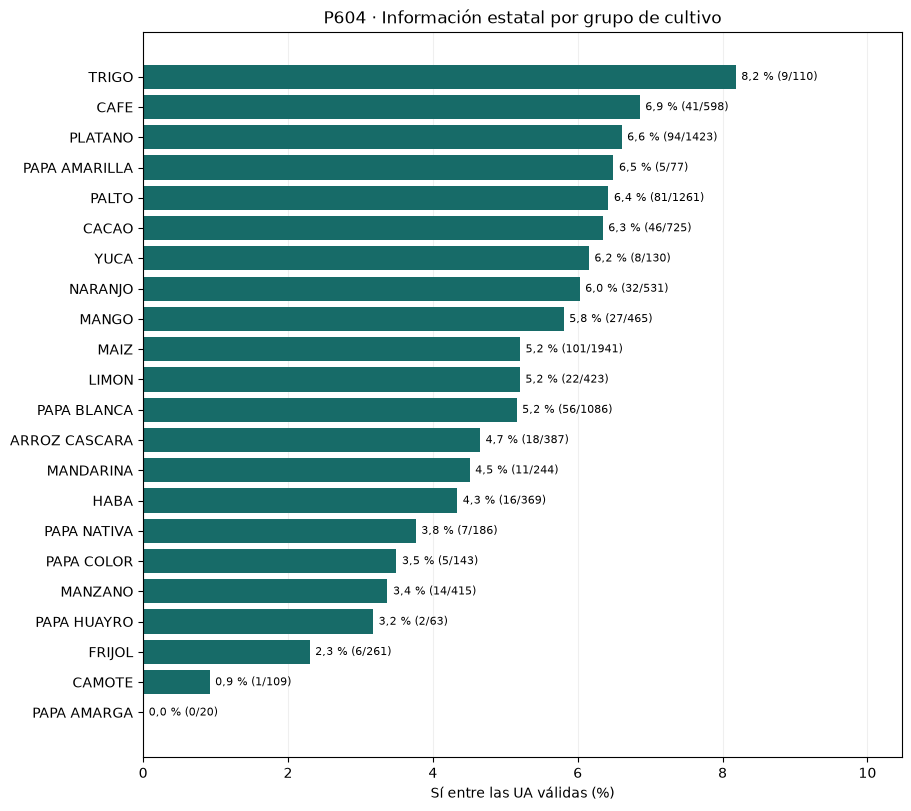

In [8]:
tabla_informacion = resumir_binaria(ua_cultivo, "cultivo_grupo", "P604", grupos_cultivo)
display(tabla_informacion.round(2))
barras_cultivo(tabla_informacion, "Sí (%)", "Sí",
               "P604 · Información estatal por grupo de cultivo", "Sí entre las UA válidas (%)")

Declararon recibir información 6 de 261 UA vinculadas a frijol (2,30 %), 16 de 369 a haba (4,34 %) y 101 de 1.941 a maíz (5,20 %). La respuesta corresponde a la UA. La pregunta no especifica a qué cultivo se dirigió la información.

## 5. Análisis 2: Conocimiento de identificación por periodo de cosecha

Pregunta: ¿Cómo varía el conocimiento declarado del requisito de identificación de productos primarios para consumo humano entre las UA vinculadas a las diferentes categorías del periodo registrado de cosecha?

Se utiliza `P607` para comparar el conocimiento declarado según las categorías de cosecha obtenidas con P206/P207. La elegibilidad se determina con `P606_7`. Cada UA se cuenta una vez por categoría y puede integrar varias categorías.

Pertenencias no aplicables (P606_7 = 1): 12 | Aplicabilidad indeterminada: 0


,UA elegibles,Sí,No,Total válido,Sin respuesta válida,Sí (%)
categoria_cosecha,,,,,,
Muy corto,4895,1149,3746,4895,0,23.47
Corto,673,181,492,673,0,26.89
Mediano,24,8,16,24,0,33.33
Largo,2017,460,1557,2017,0,22.81
Muy largo,0,0,0,0,0,NaN


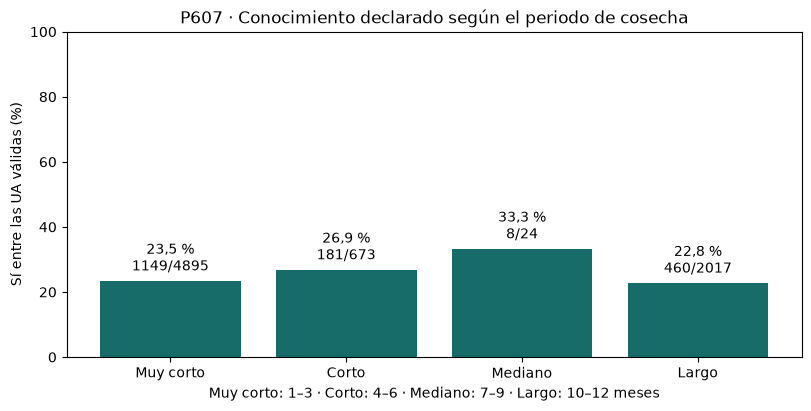

In [9]:
elegibles_p607 = ua_periodo["P606_7"].eq(0)
tabla_identificacion = resumir_binaria(
    ua_periodo.loc[elegibles_p607], "categoria_cosecha", "P607", categorias_periodo
)
print("Pertenencias no aplicables (P606_7 = 1):", ua_periodo["P606_7"].eq(1).sum(),
      "| Aplicabilidad indeterminada:", (~ua_periodo["P606_7"].isin([0, 1])).sum())
display(tabla_identificacion.round(2))

grafico = tabla_identificacion.loc[tabla_identificacion["Total válido"].gt(0)]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
barras = ax.bar(grafico.index, grafico["Sí (%)"], color="#176B68")
ax.bar_label(barras, labels=[f"{p:.1f} %\n{s}/{n}".replace(".", ",")
             for p, s, n in zip(grafico["Sí (%)"], grafico["Sí"], grafico["Total válido"])], padding=4)
ax.set(title="P607 · Conocimiento declarado según el periodo de cosecha",
       ylim=(0, 100), ylabel="Sí entre las UA válidas (%)",
       xlabel="Muy corto: 1–3 · Corto: 4–6 · Mediano: 7–9 · Largo: 10–12 meses")
plt.show()

Interpretación: Muy corto registró 1.149/4.895 (23,47 %), Corto 181/673 (26,89 %), Mediano 8/24 (33,33 %) y Largo 460/2.017 (22,81 %). Muy largo (>12 meses) carece de UA válidas y se conserva en la tabla con porcentaje vacío.

Limitación: Las categorías pueden compartir UA, Mediano tiene solo 24 casos y la comparación es descriptiva. El intervalo representa cosecha registrada y no permite atribuir cambios de conocimiento a su duración.

## 6. Análisis 3: Información estatal por departamento y cultivo

Pregunta: Dentro de cada grupo de cultivo seleccionado, ¿qué departamentos presentan porcentajes de información estatal declarada superiores o inferiores a la referencia general observada para ese mismo cultivo?

Se utiliza `P604` junto con el departamento y `cultivo_grupo` para comparar la información estatal declarada entre departamentos dentro de un mismo cultivo. Cada UA se cuenta una vez por grupo de cultivo, en su departamento.

Base del análisis: El denominador reúne las UA con respuesta 1 o 2 a P604 en cada combinación departamento–cultivo. La referencia reúne todas las UA válidas del mismo cultivo en los cinco departamentos.

Tras codificar Sí = 1 y No = 0, `transform("mean")` asigna a cada fila la proporción conjunta del cultivo. Se resta esa referencia al porcentaje departamental para obtener puntos porcentuales (pp). La referencia se calcula entre las UA individuales, por lo que cada departamento aporta según el tamaño de su base. El mapa representa las diferencias y muestra sus denominadores.

In [10]:
informacion_valida = ua_cultivo.loc[ua_cultivo["P604"].isin([1, 2])].copy()
informacion_valida["Afirmativa"] = informacion_valida["P604"].eq(1).astype(int)
informacion_valida["Referencia cultivo (%)"] = (
    100 * informacion_valida.groupby("cultivo_grupo")["Afirmativa"].transform("mean")
)
tabla_territorial = informacion_valida.groupby(
    ["cultivo_grupo", "Departamento"], as_index=False
).agg(**{
    "Total válido": ("Afirmativa", "size"),
    "Sí": ("Afirmativa", "sum"),
    "Referencia cultivo (%)": ("Referencia cultivo (%)", "first")
})
tabla_territorial["Sí (%)"] = 100 * tabla_territorial["Sí"] / tabla_territorial["Total válido"]
tabla_territorial["Diferencia (pp)"] = tabla_territorial["Sí (%)"] - tabla_territorial["Referencia cultivo (%)"]
with pd.option_context("display.max_rows", 110):
    display(tabla_territorial.round(2))

,cultivo_grupo,Departamento,Total válido,Sí,Referencia cultivo (%),Sí (%),Diferencia (pp)
0,ARROZ CASCARA,Arequipa,230,8,4.65,3.48,-1.17
1,ARROZ CASCARA,Junín,2,0,4.65,0.00,-4.65
2,ARROZ CASCARA,San Martín,155,10,4.65,6.45,1.80
3,CACAO,Junín,168,16,6.34,9.52,3.18
4,CACAO,San Martín,557,30,6.34,5.39,-0.96
5,CAFE,Junín,274,19,6.86,6.93,0.08
6,CAFE,San Martín,324,22,6.86,6.79,-0.07
7,CAMOTE,Arequipa,17,0,0.92,0.00,-0.92
8,CAMOTE,Ica,16,0,0.92,0.00,-0.92
9,CAMOTE,Lima,76,1,0.92,1.32,0.40


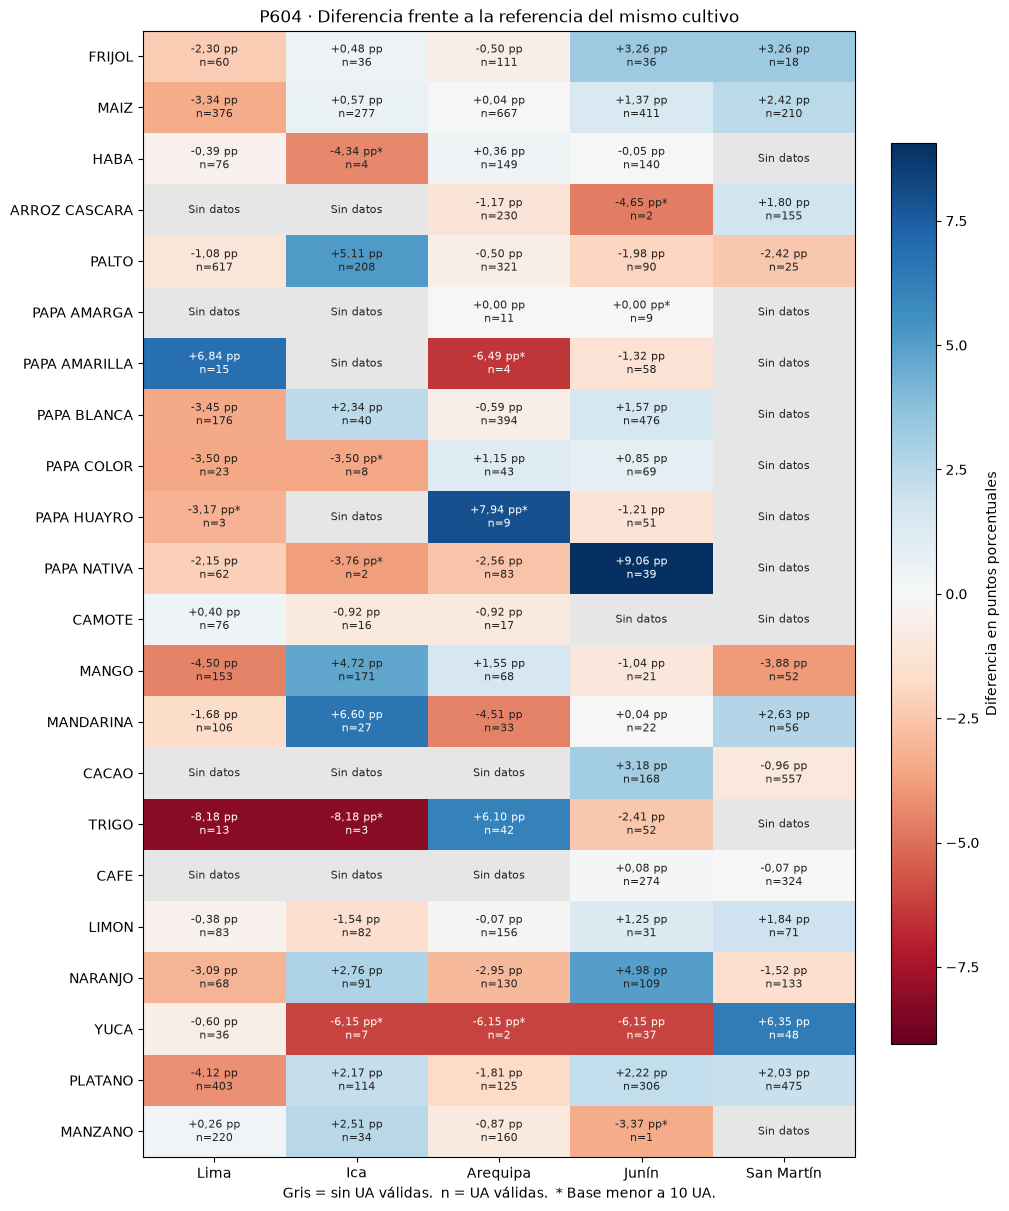

In [11]:
diferencias = tabla_territorial.pivot(
    index="cultivo_grupo", columns="Departamento", values="Diferencia (pp)"
).reindex(index=grupos_cultivo, columns=list(departamentos.values()))
bases = tabla_territorial.pivot(
    index="cultivo_grupo", columns="Departamento", values="Total válido"
).reindex_like(diferencias)
limite = max(1, diferencias.abs().max().max())
fig, ax = plt.subplots(figsize=(10, 12), layout="constrained")
colores = plt.get_cmap("RdBu").with_extremes(bad="#e6e6e6")
imagen = ax.imshow(diferencias, cmap=colores, vmin=-limite, vmax=limite, aspect="auto")
ax.set_xticks(range(len(diferencias.columns)), diferencias.columns)
ax.set_yticks(range(len(diferencias.index)), diferencias.index)
ax.set_title("P604 · Diferencia frente a la referencia del mismo cultivo")
ax.set_xlabel("Gris = sin UA válidas.  n = UA válidas.  * Base menor a 10 UA.")
fig.colorbar(imagen, ax=ax, shrink=0.8, label="Diferencia en puntos porcentuales")

for fila in range(len(diferencias.index)):
    for columna in range(len(diferencias.columns)):
        dif = diferencias.iat[fila, columna]
        n = bases.iat[fila, columna]
        etiqueta = "Sin datos"
        if pd.notna(n):
            marca = "*" if n < 10 else ""
            etiqueta = f"{dif:+.2f} pp{marca}\nn={int(n)}".replace(".", ",")
        ax.text(columna, fila, etiqueta, ha="center", va="center", fontsize=8,
                color="white" if pd.notna(dif) and abs(dif) >= 0.65 * limite else "#222222")
plt.show()

Interpretación: Para maíz, la referencia conjunta fue 101 / 1.941 (5,20 %). San Martín registró 16/210 (7,62 %), una diferencia de +2,42 pp. Lima registró 7/376 (1,86 %), una diferencia de -3,34 pp. Las diferencias se calculan antes de redondear.

## 7. Análisis 4: Uso de residuos agrícolas como abono

Pregunta: ¿Qué proporción de UA vinculadas a cada grupo de cultivo seleccionado declaró utilizar residuos agrícolas como abono?

Se utiliza `P601_4` para describir el uso de residuos agrícolas como abono en el contexto de la inocuidad. Se revisan `P601_7` y las seis opciones `P601_1` a `P601_6` para determinar la elegibilidad y la validez del bloque. Cada UA se cuenta una vez por grupo de cultivo.

Base del análisis: El denominador reúne las UA elegibles (`P601_7 = 0`) con códigos 0/1 en las seis opciones y al menos una opción marcada. Dentro de ese bloque válido, el numerador cuenta `P601_4 = 1` y el resto corresponde a «no marcó abono».

Pertenencias UA–cultivo elegibles: 10967 | Con bloque válido: 10967
No aplicables (P601_7 = 1): 0 | Aplicabilidad indeterminada: 0


,UA elegibles,Marcó abono,No marcó abono,Total válido,Bloque no válido,Marcó abono (%)
cultivo_grupo,,,,,,
FRIJOL,261,123,138,261,0,47.13
MAIZ,1941,778,1163,1941,0,40.08
HABA,369,175,194,369,0,47.43
ARROZ CASCARA,387,149,238,387,0,38.50
PALTO,1261,527,734,1261,0,41.79
PAPA AMARGA,20,2,18,20,0,10.00
PAPA AMARILLA,77,25,52,77,0,32.47
PAPA BLANCA,1086,433,653,1086,0,39.87
PAPA COLOR,143,62,81,143,0,43.36


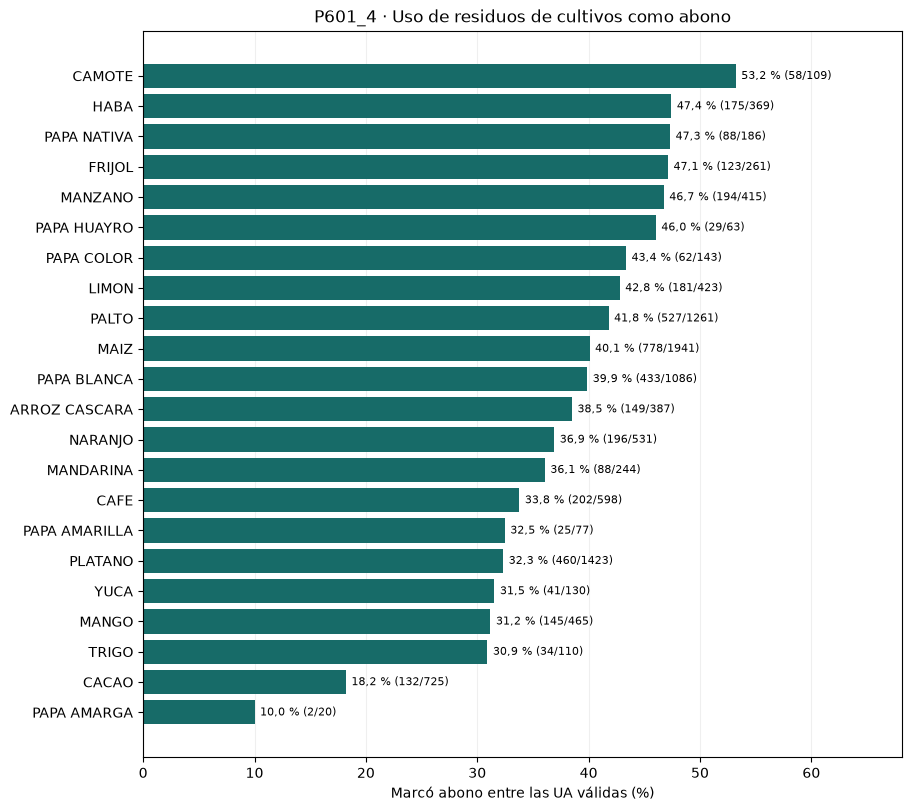

In [12]:
elegibles_abono = ua_cultivo.loc[ua_cultivo["P601_7"].eq(0)].copy()
marcas = elegibles_abono[opciones_residuos]
bloque_valido = marcas.isin([0, 1]).all(axis=1) & marcas.eq(1).any(axis=1)
# Solo se recodifica abono si el bloque es válido: 1 = marcó, 2 = no marcó.
elegibles_abono["Respuesta abono"] = elegibles_abono["P601_4"].map({1: 1, 0: 2}).where(bloque_valido)

tabla_abono = resumir_binaria(elegibles_abono, "cultivo_grupo", "Respuesta abono", grupos_cultivo)
tabla_abono = tabla_abono.rename(columns={
    "Sí": "Marcó abono", "No": "No marcó abono",
    "Sin respuesta válida": "Bloque no válido", "Sí (%)": "Marcó abono (%)"
})
print("Pertenencias UA–cultivo elegibles:", len(elegibles_abono),
      "| Con bloque válido:", bloque_valido.sum())
print("No aplicables (P601_7 = 1):", ua_cultivo["P601_7"].eq(1).sum(),
      "| Aplicabilidad indeterminada:", (~ua_cultivo["P601_7"].isin([0, 1])).sum())
display(tabla_abono.round(2))
barras_cultivo(tabla_abono, "Marcó abono (%)", "Marcó abono",
               "P601_4 · Uso de residuos de cultivos como abono", "Marcó abono entre las UA válidas (%)")

Interpretación: Marcaron abono 58 de 109 UA vinculadas a camote (53,21 %), 778 de 1.941 a maíz (40,08 %) y 132 de 725 a cacao (18,21 %). En los resultados guardados, todas las UA elegibles enlazadas aportaron un bloque válido.

Limitación: La práctica se declara para la UA. La pregunta no registra la cantidad de residuos utilizados ni identifica su cultivo de origen.

## 8. Análisis 5: Conocimiento de límites de contaminantes

Pregunta: ¿Qué proporción de UA vinculadas a cada grupo de cultivo seleccionado declaró conocer los límites máximos permisibles de contaminantes en alimentos?

Se utiliza `P605A` para describir el conocimiento declarado sobre un requisito de inocuidad, contando una UA por grupo de cultivo. La pregunta abarca alimentos de consumo humano y/o animal.

Base del análisis: El denominador reúne las UA enlazadas del grupo con respuesta 1 o 2 a P605A. Se incluyen también las que declararon No en P604. El numerador cuenta las respuestas 1.

Pertenencias con P604 = No y P605A válida: 10365


,UA elegibles,Sí,No,Total válido,Sin respuesta válida,Sí (%)
cultivo_grupo,,,,,,
FRIJOL,261,46,215,261,0,17.62
MAIZ,1941,267,1674,1941,0,13.76
HABA,369,51,318,369,0,13.82
ARROZ CASCARA,387,79,308,387,0,20.41
PALTO,1261,201,1060,1261,0,15.94
PAPA AMARGA,20,0,20,20,0,0.00
PAPA AMARILLA,77,3,74,77,0,3.90
PAPA BLANCA,1086,173,913,1086,0,15.93
PAPA COLOR,143,6,137,143,0,4.20


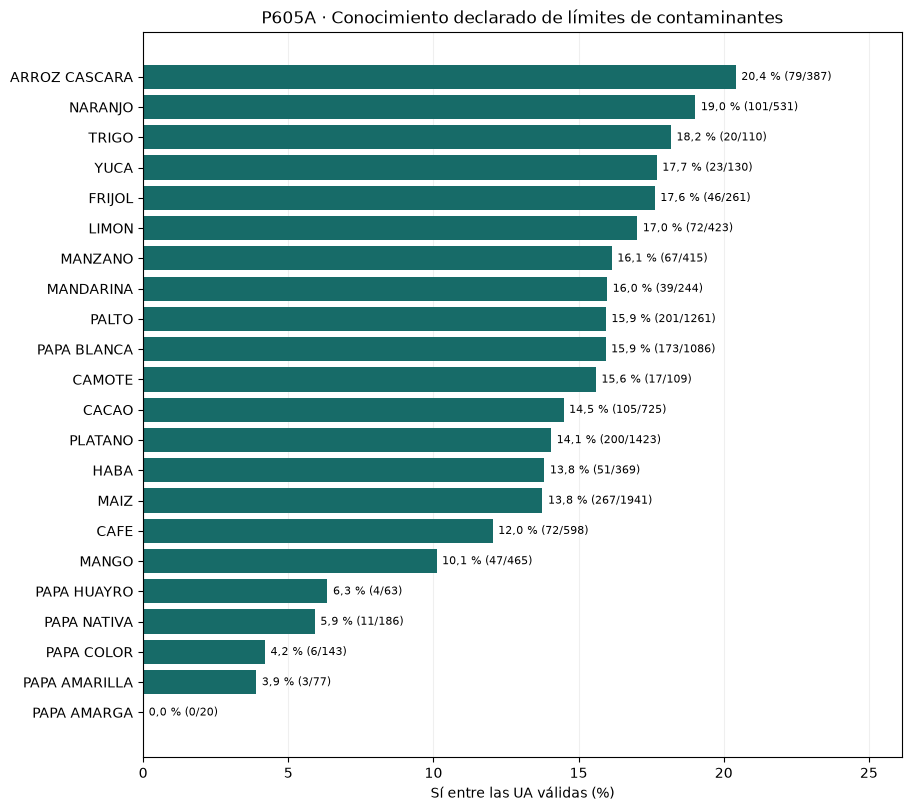

In [13]:
tabla_limites = resumir_binaria(ua_cultivo, "cultivo_grupo", "P605A", grupos_cultivo)
print("Pertenencias con P604 = No y P605A válida:",
      (ua_cultivo["P604"].eq(2) & ua_cultivo["P605A"].isin([1, 2])).sum())
display(tabla_limites.round(2))
barras_cultivo(tabla_limites, "Sí (%)", "Sí",
               "P605A · Conocimiento declarado de límites de contaminantes", "Sí entre las UA válidas (%)")

Declararon conocer los límites 79 de 387 UA vinculadas a arroz cáscara (20,41 %) y 267 de 1.941 a maíz (13,76 %). En maíz, la información estatal de P604 alcanzó el 5,20 %. Cada proporción describe una respuesta distinta del cuestionario